<a href="https://colab.research.google.com/github/okuchap/GB656_2026_public/blob/main/module8/GB656_08_CarExample.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Used Car Prices

In this example, we consider a **regression problem** where we predict the prices of used cars. The features are attributes of the cars. The data originate from Kaggle's [Regression of Used Car Prices competition](https://www.kaggle.com/competitions/playground-series-s4e9).

## Business Setting

Here is an example of a hypothetical business setting where this predictive problem would be relevant:

"I work on a team for Autotrader and we want to provide our clients a simple way of obtaining price estimates for how much their car is worth. By providing potential sellers information on how much to expect, we believe the process will go smoother if they have a good assessment of how much their cars will be worth."

## Exploring and Preparing the Data

We start by loading and exploring the data. The exploration is going to be key in informing our modeling process.

### Loading Data

Let's load relevant packages and the data:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
# Course data are loaded directly from the 2026 public repository below.
# You do not need to clone a repository or upload data in Colab.

The labeled dataset is stored in two CSV parts. We concatenate those parts to obtain the full labeled dataset. The original Kaggle competition also provided an unlabeled file for generating predictions. This example uses the labeled data so we can measure prediction error against observed prices.

In [3]:
car_dat_1 = pd.read_csv('https://raw.githubusercontent.com/okuchap/GB656_2026_public/main/module8/GB656_08_train_1.csv')
car_dat_2 = pd.read_csv('https://raw.githubusercontent.com/okuchap/GB656_2026_public/main/module8/GB656_08_train_2.csv')
car_dat = pd.concat([car_dat_1, car_dat_2], ignore_index=True)

### Reserving a final test set

Before exploring the data, randomly reserve 25% of the labeled rows. The remaining rows are our development data. We use them for exploration, preparation, and fitting. We open the final test set for the comparison at the end.

In [4]:
development_data, final_test_data = train_test_split(
    car_dat, test_size=0.25, random_state=42
)
print(f"Development rows: {len(development_data):,}")
print(f"Final test rows: {len(final_test_data):,}")

Development rows: 141,399
Final test rows: 47,134


### Exploring the data

Let's look at the development rows:

In [5]:
development_data.head()

,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
22284,22284,Audi,A5 2.0T Premium,2013,115000,Gasoline,211.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,White,Beige,None reported,Yes,11500
179159,179159,Dodge,Dakota SLT Quad Cab,2007,91545,Gasoline,210.0HP 3.7L V6 Cylinder Engine Gasoline Fuel,A/T,Black,Gray,None reported,Yes,10999
121676,121676,Audi,R8 Base,2008,568,Gasoline,420.0HP 4.2L 8 Cylinder Engine Gasoline Fuel,6-Speed M/T,Yellow,Black,None reported,Yes,56000
127736,127736,Mercedes-Benz,AMG GT Base,2022,6581,Gasoline,469.0HP 4.0L 8 Cylinder Engine Gasoline Fuel,9-Speed A/T,White,Black,None reported,Yes,44900
54582,54582,Nissan,Armada LE,2011,120000,Gasoline,305.0HP 5.6L 8 Cylinder Engine Gasoline Fuel,A/T,Black,Black,None reported,Yes,8500


In [6]:
development_data.info()
development_data.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 141399 entries, 22284 to 121958
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            141399 non-null  int64 
 1   brand         141399 non-null  object
 2   model         141399 non-null  object
 3   model_year    141399 non-null  int64 
 4   milage        141399 non-null  int64 
 5   fuel_type     137587 non-null  object
 6   engine        141399 non-null  object
 7   transmission  141399 non-null  object
 8   ext_col       141399 non-null  object
 9   int_col       141399 non-null  object
 10  accident      139552 non-null  object
 11  clean_title   125406 non-null  object
 12  price         141399 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 15.1+ MB


,id,model_year,milage,price
count,141399.000000,141399.000000,141399.000000,1.413990e+05
mean,94189.225985,2015.826682,65748.728513,4.399703e+04
std,54396.693383,5.657009,49793.770307,8.096835e+04
min,1.000000,1974.000000,100.000000,2.000000e+03
25%,47166.500000,2013.000000,24300.000000,1.700000e+04
50%,94139.000000,2017.000000,57785.000000,3.079800e+04
75%,141220.500000,2020.000000,95400.000000,4.990000e+04
max,188532.000000,2024.000000,405000.000000,2.954083e+06


Mileage and model year are numeric predictors. We use `price` as the target and leave the row identifier out of the model. Let's look at the categorical features:

In [7]:
for column in development_data.select_dtypes(include=['object']):
    levels = development_data[column].unique()
    print(f"{column}: {len(levels)} levels. Examples: {levels[:6]}")

brand: 57 levels. Examples: ['Audi' 'Dodge' 'Mercedes-Benz' 'Nissan' 'RAM' 'BMW']
model: 1897 levels. Examples: ['A5 2.0T Premium' 'Dakota SLT Quad Cab' 'R8 Base' 'AMG GT Base'
 'Armada LE' '1500 Limited']
fuel_type: 8 levels. Examples: ['Gasoline' 'Hybrid' 'Diesel' '–' nan 'E85 Flex Fuel']
engine: 1115 levels. Examples: ['211.0HP 2.0L 4 Cylinder Engine Gasoline Fuel'
 '210.0HP 3.7L V6 Cylinder Engine Gasoline Fuel'
 '420.0HP 4.2L 8 Cylinder Engine Gasoline Fuel'
 '469.0HP 4.0L 8 Cylinder Engine Gasoline Fuel'
 '305.0HP 5.6L 8 Cylinder Engine Gasoline Fuel'
 '395.0HP 5.7L 8 Cylinder Engine Gasoline/Mild Electric Hybrid']
transmission: 52 levels. Examples: ['Transmission w/Dual Shift Mode' 'A/T' '6-Speed M/T' '9-Speed A/T'
 '8-Speed A/T' 'Automatic']
ext_col: 319 levels. Examples: ['White' 'Black' 'Yellow' 'Gray' 'Brown' '–']
int_col: 156 levels. Examples: ['Beige' 'Gray' 'Black' '–' 'Macchiato/Magmagrey' 'Red']
accident: 3 levels. Examples: ['None reported' 'At least 1 accident or dama

So, it appears that a few variables (accident, clean_title) have only a few categories. However, others (model, engine, color) have many levels! We will need to contemplate how to deal with that.

Let's check if there are missing variables:

In [8]:
development_data.isna().sum()

id                  0
brand               0
model               0
model_year          0
milage              0
fuel_type        3812
engine              0
transmission        0
ext_col             0
int_col             0
accident         1847
clean_title     15993
price               0
dtype: int64

### Preparing the data

We use the same rules to turn each car's raw fields into features. These rules work one row at a time and use information available when making a prediction:

- Use the engine description to distinguish hybrid and electric cars, with gas as the default. Extract horsepower, engine size, and cylinder count where the description provides them.
- Use broad color names for the exterior and interior. Label unrecognized colors and missing accident, title, or fuel information as `No info`.
- Leave out the raw engine, model, and transmission text and the row identifier.

In [9]:
def extract_color(value):
    colors = ['Black', 'White', 'Gray', 'Silver', 'Blue', 'Red', 'Brown',
              'Green', 'Gold', 'Beige', 'Orange', 'Purple']
    for color in colors:
        if color in str(value):
            return color
    return 'No info'


def prepare_features(data):
    features = data[['model_year', 'milage', 'brand', 'accident', 'clean_title',
                     'ext_col', 'int_col', 'fuel_type']].copy()
    engine = data['engine']
    features['cartype'] = np.select(
        [engine.str.contains('Hybrid', na=False).to_numpy(dtype=bool),
         engine.str.contains('Electric', na=False).to_numpy(dtype=bool)],
        ['H', 'E'],
        default='G',
    )
    features['horsepower'] = engine.str.extract(r'(\d+\.\d+)HP', expand=False).astype(float)
    features['size'] = engine.str.extract(r'(\d+\.\d+)\s*(?:L|Liter)', expand=False).astype(float)
    features['Cylinders'] = engine.str.extract(r'(\d+)\s*Cylinder', expand=False).astype(float)

    for column in ['accident', 'clean_title']:
        features[column] = features[column].fillna('No info')
    for column in ['ext_col', 'int_col']:
        features[column] = features[column].map(extract_color)
    features['fuel_type'] = features['fuel_type'].replace(
        ['-', '–', 'not supported'], 'No info'
    ).fillna('No info')
    return features


development_features = prepare_features(development_data)
development_features.head()

,model_year,milage,brand,accident,clean_title,ext_col,int_col,fuel_type,cartype,horsepower,size,Cylinders
22284,2013,115000,Audi,None reported,Yes,White,Beige,Gasoline,G,211.0,2.0,4.0
179159,2007,91545,Dodge,None reported,Yes,Black,Gray,Gasoline,G,210.0,3.7,6.0
121676,2008,568,Audi,None reported,Yes,No info,Black,Gasoline,G,420.0,4.2,8.0
127736,2022,6581,Mercedes-Benz,None reported,Yes,White,Black,Gasoline,G,469.0,4.0,8.0
54582,2011,120000,Nissan,None reported,Yes,Black,Black,Gasoline,G,305.0,5.6,8.0


Let's check how often the engine descriptions leave a numeric feature missing:

In [10]:
development_features.isna().sum()

model_year         0
milage             0
brand              0
accident           0
clean_title        0
ext_col            0
int_col            0
fuel_type          0
cartype            0
horsepower     24911
size            5046
Cylinders      28367
dtype: int64

We fill missing numeric values with their development-set means, then standardize the numeric features to help the least-squares solver handle different units. We fit these steps and the one-hot encoding on the development data and reuse the fitted preprocessing for the final test set. The encoder can still produce the same feature columns if it encounters a new category.

In [11]:
numeric_columns = ['model_year', 'milage', 'horsepower', 'size', 'Cylinders']
categorical_columns = ['brand', 'accident', 'clean_title', 'cartype',
                       'ext_col', 'int_col', 'fuel_type']

numeric_preprocessor = make_pipeline(
    SimpleImputer(strategy='mean'),
    StandardScaler(),
)
preprocessor = ColumnTransformer([
    ('numeric', numeric_preprocessor, numeric_columns),
    ('categorical', OneHotEncoder(
        drop='first', handle_unknown='ignore', sparse_output=False
    ), categorical_columns),
])
X_train = preprocessor.fit_transform(development_features)
y_train = development_data['price']

## Modeling

Our benchmark is ordinary least squares (OLS) using all development rows and the prepared features.

In [12]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

### Assessing the development fit

We compare fitted prices with observed prices on the development data. The residuals help diagnose the fit. We use the final test set later to measure out-of-sample prediction error.

In [13]:
y_train_preds = model.predict(X_train)

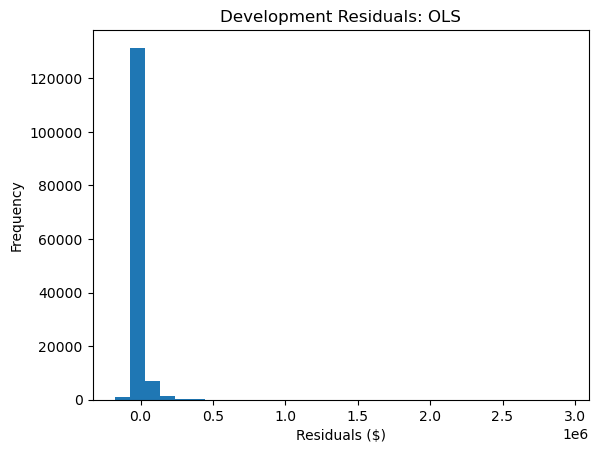

In [14]:
residuals = y_train - y_train_preds

plt.hist(residuals, bins=30)
plt.xlabel("Residuals ($)")
plt.ylabel("Frequency")
plt.title("Development Residuals: OLS")
plt.show()

Some large residuals may be associated with exceptionally high recorded prices. As a sensitivity check, we fit a second OLS model after excluding development rows with prices above the development-set 99.9th percentile. We use the same prepared features in both models so the comparison shows the effect of trimming the rows used to fit OLS.

In [15]:
percentile_99_9 = y_train.quantile(0.999)
keep_for_filtered_fit = y_train <= percentile_99_9
X_train_filtered = X_train[keep_for_filtered_fit.to_numpy()]
y_train_filtered = y_train[keep_for_filtered_fit]

print(f"Development price cutoff: ${percentile_99_9:,.0f}")
print(f"Rows used in the filtered fit: {len(y_train_filtered):,} of {len(y_train):,}")

Development price cutoff: $749,950
Rows used in the filtered fit: 141,280 of 141,399


Let's fit the second model and look at residuals for the rows it used:

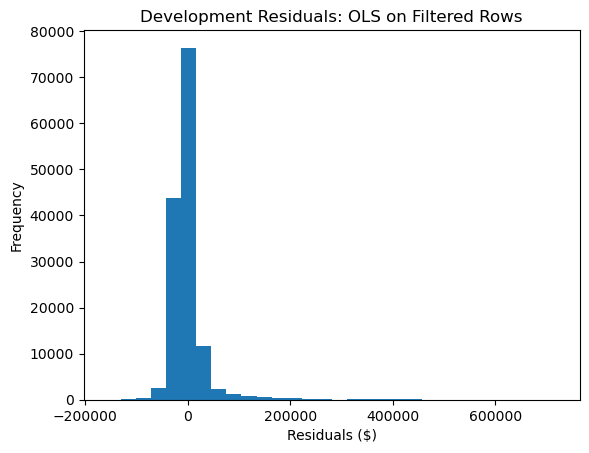

In [16]:
model_filtered = LinearRegression()
model_filtered.fit(X_train_filtered, y_train_filtered)

y_train_preds_filtered = model_filtered.predict(X_train_filtered)
residuals_filtered = y_train_filtered - y_train_preds_filtered

plt.hist(residuals_filtered, bins=30)
plt.xlabel("Residuals ($)")
plt.ylabel("Frequency")
plt.title("Development Residuals: OLS on Filtered Rows")
plt.show()

### Comparing the models on the final test set

We use every labeled final test row for both models, including cars with extreme prices. We use root mean squared error (RMSE), which measures prediction error in dollars and gives more weight to large misses.

Unconstrained OLS can estimate negative prices. We report the count and percentage of negative estimates to show this limitation for sellers. We calculate RMSE using the original predictions.

In [17]:
final_test_features = prepare_features(final_test_data)
X_test = preprocessor.transform(final_test_features)
y_test = final_test_data['price']

test_predictions = [model.predict(X_test), model_filtered.predict(X_test)]
negative_estimates = [predictions < 0 for predictions in test_predictions]

pd.DataFrame({
    'Model': ['OLS', 'OLS with upper-tail training prices excluded'],
    'Final test RMSE ($)': [
        np.sqrt(mean_squared_error(y_test, predictions))
        for predictions in test_predictions
    ],
    'Negative estimates': [mask.sum() for mask in negative_estimates],
    'Negative estimates (%)': [100 * mask.mean() for mask in negative_estimates],
}).round(2)

,Model,Final test RMSE ($),Negative estimates,Negative estimates (%)
0,OLS,66892.90,2381,5.05
1,OLS with upper-tail training prices excluded,66887.92,2378,5.05


The residual plots use different development rows, so judge the effect of filtering using the RMSE comparison on the common final test set. Discuss whether the difference matters for a seller using the estimates. Keep in mind that the errors here reflect this dataset and split. The comparison uses a fixed cutoff for the sensitivity check.

For the 2026 final project, submit your report PDF and reproducible code through Canvas.